In [ ]:
import scipy
print(scipy.__version__)

1.16.3


In [ ]:
!wget "https://s3.ap-northeast-1.wasabisys.com/gigadb-datasets/live/pub/10.5524/100001_101000/100542/session1/s1/sess01_subj01_EEG_ERP.mat" -O eeg.mat

--2026-10-29 18:50:49--  https://s3.ap-northeast-1.wasabisys.com/gigadb-datasets/live/pub/10.5524/100001_101000/100542/session1/s1/sess01_subj01_EEG_ERP.mat
Resolving s3.ap-northeast-1.wasabisys.com (s3.ap-northeast-1.wasabisys.com)... 103.151.85.104, 103.151.85.102, 103.151.85.101, ...
Connecting to s3.ap-northeast-1.wasabisys.com (s3.ap-northeast-1.wasabisys.com)|103.151.85.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 949889154 (906M) [application/octet-stream]
Saving to: ‘eeg.mat’

eeg.mat             100%[===================>] 905.88M  24.8MB/s    in 37s     

2026-10-29 18:51:28 (24.2 MB/s) - ‘eeg.mat’ saved [949889154/949889154]



In [ ]:
import hashlib
with open("eeg.mat", "rb") as f:
    print(hashlib.file_digest(f, "sha256").hexdigest())

8cb4217a6f72466448b8259bb8f072c25f81437c075b0619ea14686eea0848b2


In [ ]:
from scipy.io import loadmat

m = loadmat("eeg.mat", variable_names=["EEG_ERP_test"],
            struct_as_record=False, squeeze_me=True)
d = m["EEG_ERP_test"]
print("EEG array shape:", d.smt.shape)

EEG array shape: (800, 2160, 62)


In [ ]:
print(d.smt[:10, 0, 0])

[ 5.19650661  5.79649746  7.99649441  6.79649746 10.89650356 13.29649746
 14.09650051 17.39650356 15.39650356 16.79649746]


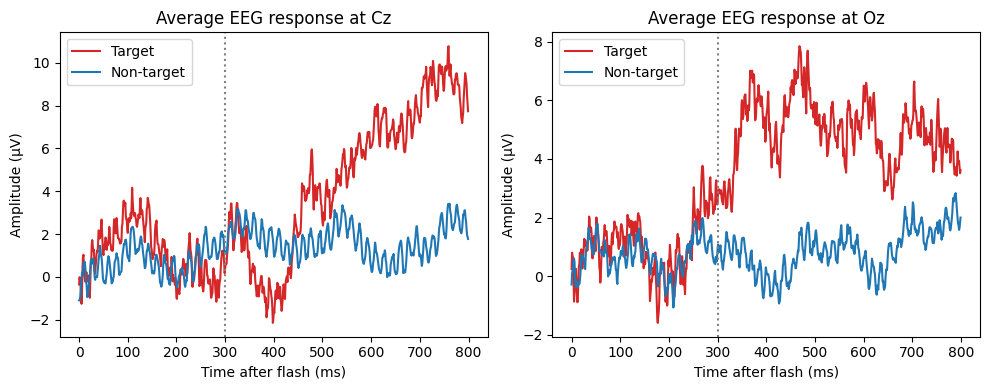

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

y = np.ravel(d.y_dec)
t_ms = np.arange(d.smt.shape[0]) * 1000 / d.fs

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, ch_name in zip(axes, ['Cz', 'Oz']):
    i = list(d.chan).index(ch_name)
    target = d.smt[:, y == 1, i].mean(axis=1)
    non_target = d.smt[:, y == 2, i].mean(axis=1)

    ax.plot(t_ms, target, color='tab:red', label='Target')
    ax.plot(t_ms, non_target, color='tab:blue', label='Non-target')
    ax.axvline(300, color='gray', linestyle=':')
    ax.set_title(f'Average EEG response at {ch_name}')
    ax.set_xlabel('Time after flash (ms)')
    ax.set_ylabel('Amplitude (µV)')
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
import urllib.request
url = "https://s3.ap-northeast-1.wasabisys.com/gigadb-datasets/live/pub/10.5524/100001_101000/100542/session1/s1/sess01_subj01_EEG_ERP.mat"
urllib.request.urlretrieve(url, "eeg.mat")
print("done")

done
